# 02 · Language Modeling - Building makemore

We implement a bigram character-level language model, which we will further complexify in followup videos into a modern Transformer language model, like GPT. In this video, the focus is on (1) introducing torch.Tensor and its subtleties and use in efficiently evaluating neural networks and (2) the overall framework of language modeling that includes model training, sampling, and the evaluation of a loss (e.g. the negative log likelihood for classification).

Working through [Andrej Karpathy's *Neural Networks: Zero to Hero*](https://karpathy.ai/zero-to-hero.html),
lecture 2 (makemore).


In [57]:
words = open('names.txt', 'r').read().splitlines()
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [58]:
len(words)

32033

In [59]:
min(len(w) for w in words)

2

In [60]:
max(len(w) for w in words)

15

In [61]:
#Bigram model development as an example.

for w in words[:1]:
    for ch1, ch2 in zip(w, w[1:]):
        print(ch1, ch2)


e m
m m
m a


In [62]:
# using start and end tokens to mark the beginning and end of a word

for w in words[:1]:
    chs = ['<S>'] + list(w) + ['<E>']
    for ch1, ch2 in zip(chs, chs[1:]):
        print(ch1, ch2)

<S> e
e m
m m
m a
a <E>


In [63]:
# tracking the counts of each bigram in a dictionary
b = {}

for w in words:
    chs = ['<S>'] + list(w) + ['<E>']
    for ch1, ch2 in zip(chs, chs[1:]):
        bigram = (ch1, ch2)
        b[bigram] = b.get(bigram, 0) + 1
        #print(ch1, ch2)

In [64]:
sorted(b.items(), key=lambda kv: -kv[1])

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

In [65]:
# using pytorch to create a 2d array of bigram counts
import torch

In [69]:
N = torch.zeros((28, 28), dtype=torch.int32)

In [70]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i for i,s in enumerate(chars)}
stoi['<S>'] = 26
stoi['<E>'] = 27

In [74]:
itos = {i:s for s,i in stoi.items()}

In [75]:
for w in words:
    chs = ['<S>'] + list(w) + ['<E>']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        N[ix1, ix2] += 1

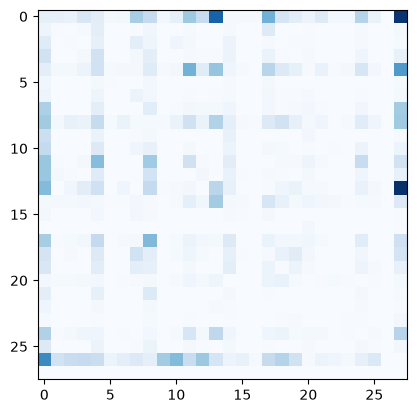

In [77]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.imshow(N, cmap='Blues')